<a href="https://colab.research.google.com/github/ramyasetty789-gif/Project/blob/main/Marketing_Campaigns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Steps as per project requirements
1- Data Import
2- Investigate Variables
3- Missing Value Imputation
4- Create Variables
5- Box Plots and Histograms
6- Encoding
7- Correlation Analysis
8- Hypothesis Testing
9- Visualization

### STEP-1: Importing data/files
# 1.1: Import the necessary libraries (pandas, matplotlib.pyplot, seaborn, numpy, and scipy.stats)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
import scipy.stats as stats

1.2: Read the CSV file (marketing_data.csv) using pd.read_csv() and store it in a DataFrame (data)

In [2]:
data = pd.read_csv('marketing_data.csv')

1.3: Print a snapshot of the data (data.head()) and check the data types and missing values (data.info())

In [5]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   2240 non-null   int64 
 1   Year_Birth           2240 non-null   int64 
 2   Education            2240 non-null   object
 3   Marital_Status       2240 non-null   object
 4    Income              2216 non-null   object
 5   Kidhome              2240 non-null   int64 
 6   Teenhome             2240 non-null   int64 
 7   Dt_Customer          2240 non-null   object
 8   Recency              2240 non-null   int64 
 9   MntWines             2240 non-null   int64 
 10  MntFruits            2240 non-null   int64 
 11  MntMeatProducts      2240 non-null   int64 
 12  MntFishProducts      2240 non-null   int64 
 13  MntSweetProducts     2240 non-null   int64 
 14  MntGoldProds         2240 non-null   int64 
 15  NumDealsPurchases    2240 non-null   int64 
 16  NumWeb

STEP 2: Investigate Variables

2.1: Check variables like Dt_Customer and Income to ensure they are imported correctly

In [8]:
data.columns = data.columns.str.replace(' ', '').str.lower()

2.2: Convert the income column to a float by removing '$' and ',' and using astype('float')

In [9]:
data['income'] = data['income'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip().astype(float)
print(data['income'].dtypes)
display(data[['income']].head())

float64


,income
0,84835.0
1,57091.0
2,67267.0
3,32474.0
4,21474.0


2.3: Convert the Dt_Customer column to a datetime object using pd.to_datetime()

In [10]:
data['dt_customer'] = pd.to_datetime(data['dt_customer'])
print(data['dt_customer'].dtypes)
display(data[['dt_customer']].head())

datetime64[ns]


/tmp/ipykernel_759/1647492558.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['dt_customer'] = pd.to_datetime(data['dt_customer'])


,dt_customer
0,2014-06-16
1,2014-06-15
2,2014-05-13
3,2014-05-11
4,2014-04-08


STEP 3: Missing Value Imputation

3.1: Check for missing values using data.isnull().sum()

In [11]:
data.isnull().sum()

,0
id,0
year_birth,0
education,0
marital_status,0
income,24
kidhome,0
teenhome,0
dt_customer,0
recency,0
mntwines,0


3.2: Clean the marital_status and education categories (e.g., combining similar categories)

In [12]:
# Inspect current values
print("Before Cleaning:")
print(data['marital_status'].value_counts())
print(data['education'].value_counts())

# Group marital status categories
marital_map = {
    'Married': 'Partner',
    'Together': 'Partner',
    'Single': 'Single',
    'Divorced': 'Single',
    'Widow': 'Single',
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
}
data['marital_status'] = data['marital_status'].map(marital_map)

# Group education categories
education_map = {
    'Graduation': 'Graduate',
    'PhD': 'Postgraduate',
    'Master': 'Postgraduate',
    '2n Cycle': 'Undergraduate',
    'Basic': 'Undergraduate'
}
data['education'] = data['education'].map(education_map)

print("\nAfter Cleaning:")
print(data['marital_status'].value_counts())
print(data['education'].value_counts())

Before Cleaning:
marital_status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64
education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

After Cleaning:
marital_status
Partner    1444
Single      796
Name: count, dtype: int64
education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64


3.3: Impute missing income values based on similar education and marital_status categories' average incomes

In [24]:
def change(x):
  if x in ['Partner']:
    return 'couple'
  else:
    return 'Single'
data.marital_status = data.marital_status.apply(change)

In [25]:
agg_data = data.groupby(['education', 'marital_status'])[['income']].mean().unstack()['income']
agg_data

marital_status,Single
education,
Graduate,52720.077482
Postgraduate,54753.770455
Undergraduate,41823.621348


In [26]:
data['income'] = data['income'].fillna(data.groupby(['education', 'marital_status'])['income'].transform('mean'))

# Verify that there are no more missing values in the income column
print("Remaining missing income values:", data['income'].isnull().sum())

Remaining missing income values: 0


STEP 4: Create Variables

4.1: Calculate the age of customers based on year_birth considering until 2026

In [31]:
data['age'] = 2026 - data['year_birth']
display(data[['year_birth', 'age']].head())

,year_birth,age
0,1970,56
1,1961,65
2,1958,68
3,1967,59
4,1989,37


4.2: Calculate spending as the sum of spending columns (mntwines, mntfruits, etc.)

In [32]:
data['total_spending'] = data.filter(regex='^mnt').sum(axis=1)
display(data[['total_spending']].head())

,total_spending
0,1190
1,577
2,251
3,11
4,91


4.3: Calculate children_count as the sum of kidhome and teenhome.

In [34]:
data['children_count'] = data['kidhome'] + data['teenhome']
display(data[['kidhome', 'teenhome', 'children_count']].head())

,kidhome,teenhome,children_count
0,0,0,0
1,0,0,0
2,0,1,1
3,1,1,2
4,1,0,1


4.4: Create a binary variable has_children indicating if a customer has children

In [36]:
data['has_children'] = (data['children_count'] > 0).astype(int)
display(data[['children_count', 'has_children']].head())

,children_count,has_children
0,0,0
1,0,0
2,1,1
3,2,1
4,1,1


4.5: Derive total_purchases from the sum of purchase columns

In [37]:
data['total_purchases'] = data.filter(regex='purchases$').sum(axis=1)
display(data[['total_purchases']].head())

,total_purchases
0,15
1,18
2,11
3,4
4,8


STEP 5:Box Plots and Histograms

5.1: Plot box plots and histograms for numerical variables (income, spending, age, total_purchases) to understand their distributions and identify outliers

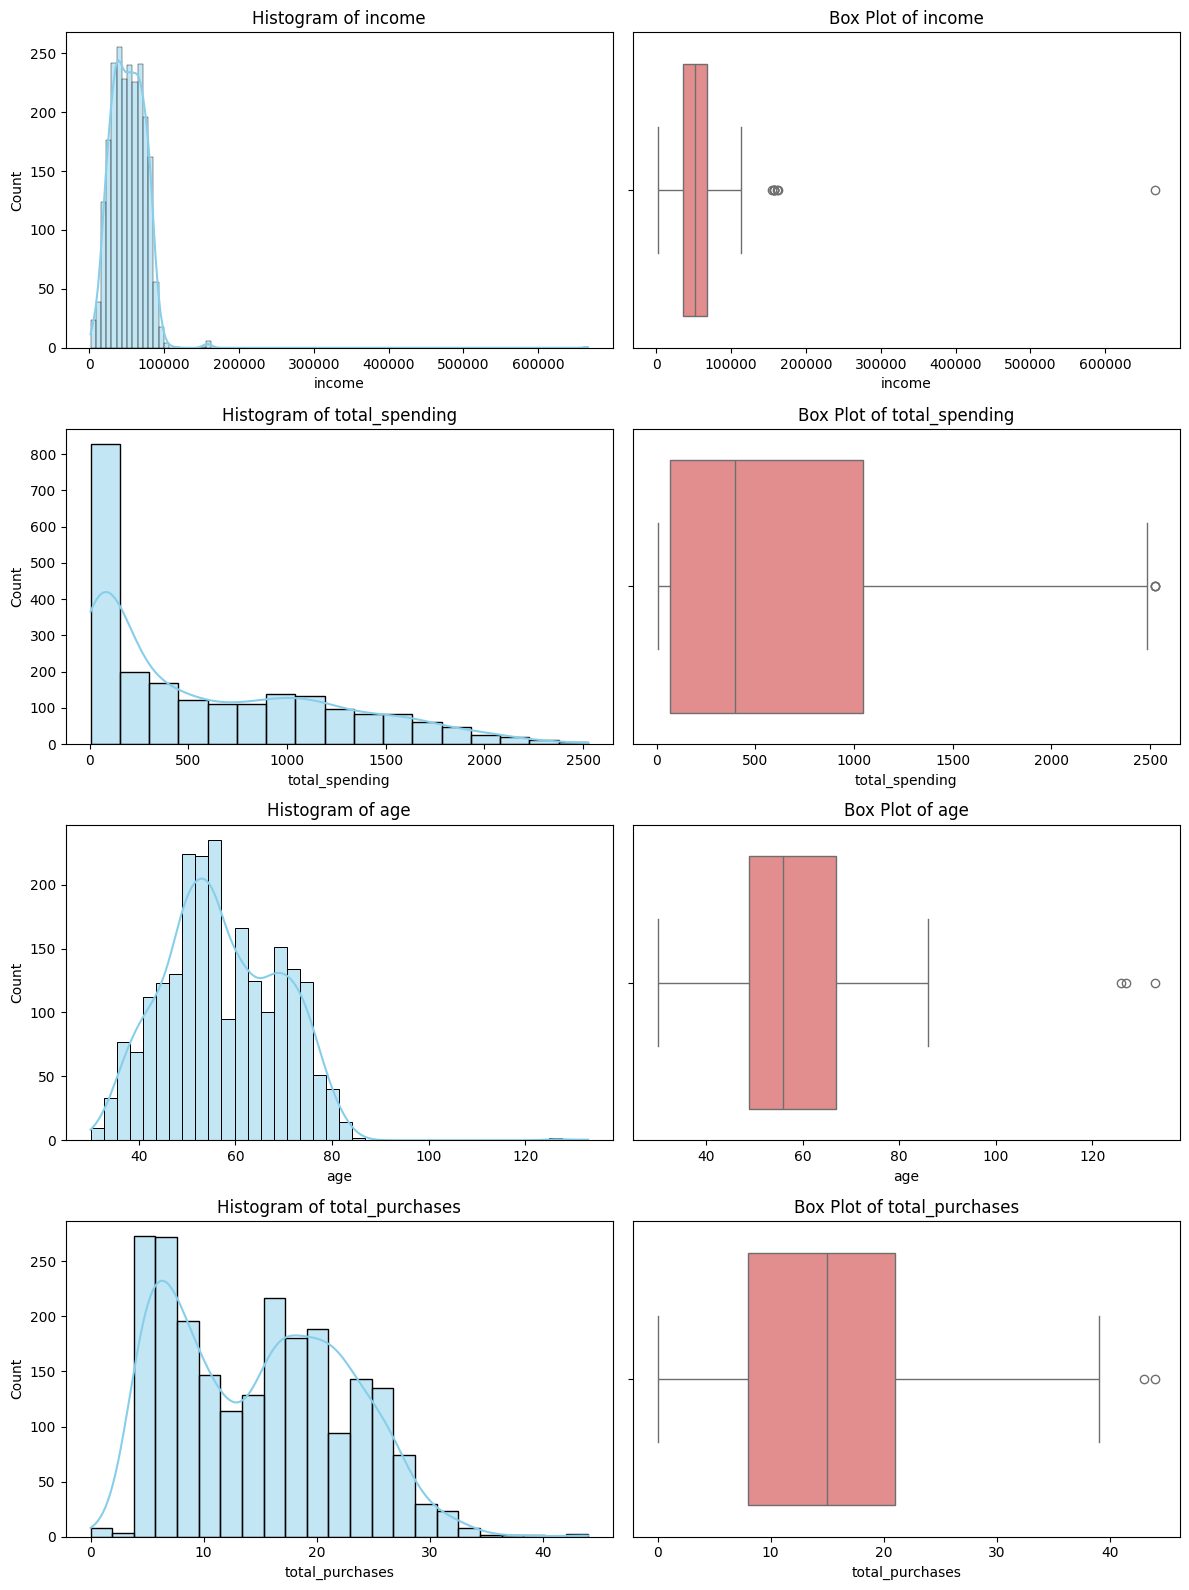

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['income', 'total_spending', 'age', 'total_purchases']
fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, col in enumerate(cols):
    # Histogram with KDE
    sns.histplot(data[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram of {col}')

    # Box Plot
    sns.boxplot(x=data[col], ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

5.2: Perform outlier treatment by capping the outliers to the upper and lower limits

In [39]:
cols = ['income', 'total_spending', 'age', 'total_purchases']

for col in cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Cap the outliers
    data[col] = data[col].clip(lower=lower_limit, upper=upper_limit)

print("Outliers successfully capped for:", cols)
display(data[cols].describe())

Outliers successfully capped for: ['income', 'total_spending', 'age', 'total_purchases']


,income,total_spending,age,total_purchases
count,2240.000000,2240.000000,2240.000000,2240.000000
mean,51874.964071,605.779408,57.147768,14.859375
std,20940.418310,602.189559,11.771725,7.667679
min,1730.000000,5.000000,30.000000,0.000000
25%,35538.750000,68.750000,49.000000,8.000000
50%,51609.500000,396.000000,56.000000,15.000000
75%,68289.750000,1045.500000,67.000000,21.000000
max,117416.250000,2510.625000,94.000000,40.500000


STEP 6: Encoding

6.1: Use ordinal encoding for the education column

In [41]:
# Define order and apply Ordinal Encoding
edu_categories = ['Undergraduate', 'Graduate', 'Postgraduate']
encoder = OrdinalEncoder(categories=[edu_categories])
data['education_encoded'] = encoder.fit_transform(data[['education']])

# Display verification
display(data[['education', 'education_encoded']].drop_duplicates())

,education,education_encoded
0,Graduate,1.0
5,Postgraduate,2.0
6,Undergraduate,0.0


6.2: Use one-hot encoding for the country and marital_status columns

In [42]:
# One-hot encode country and marital_status
data = pd.get_dummies(data, columns=['country', 'marital_status'], dtype=int)

# Display sample columns to verify the encoding
display(data.filter(regex='country_|marital_status_').head())

,country_AUS,country_CA,country_GER,country_IND,country_ME,country_SA,country_SP,country_US,marital_status_Single
0,0,0,0,0,0,0,1,0,1
1,0,1,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,1,1
3,1,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,1,0,1


STEP7: Correlation Analysis

7.1: Select a subset of columns for correlation analysis

In [43]:
# Select subset of columns for correlation analysis
subset_cols = ['income', 'total_spending', 'age', 'total_purchases', 'children_count']
corr_matrix = data[subset_cols].corr()

# Display the correlation matrix
display(corr_matrix)

,income,total_spending,age,total_purchases,children_count
income,1.000000,0.803661,0.204528,0.679880,-0.345281
total_spending,0.803661,1.000000,0.113313,0.754236,-0.498898
age,0.204528,0.113313,1.000000,0.175382,0.093232
total_purchases,0.679880,0.754236,0.175382,1.000000,-0.245846
children_count,-0.345281,-0.498898,0.093232,-0.245846,1.000000


7.2: Compute the correlation matrix (new_data[var_cor].corr()) and plot a heatmap (sns.heatmap())

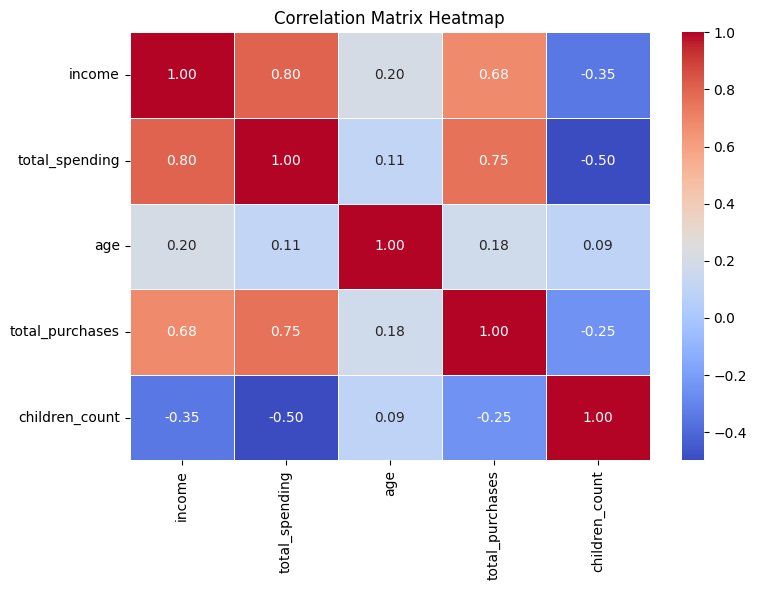

In [45]:
# Select variables for correlation
var_cor = ['income', 'total_spending', 'age', 'total_purchases', 'children_count']
correlation_matrix = data[var_cor].corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

STEP 8: Hypothesis Testing

8.1: Define and test hypotheses related to customer behavior using statistical tests (stats.ttest_ind())

In [46]:
# Hypothesis: Customers with children have different spending habits than those without children.
group_with_kids = data[data['has_children'] == 1]['total_spending']
group_no_kids = data[data['has_children'] == 0]['total_spending']

# Perform Two-Sample Independent T-Test
t_stat, p_val = stats.ttest_ind(group_with_kids, group_no_kids, equal_var=False)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}")

T-statistic: -25.0732
P-value: 1.7051e-105


STEP 9: Visualization

9.1: Visualize the performance of products (prod_data) using a bar plot

/tmp/ipykernel_759/1948685226.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=prod_data.sort_values(by='Total_Sales', ascending=False), x='Product', y='Total_Sales', palette='viridis')


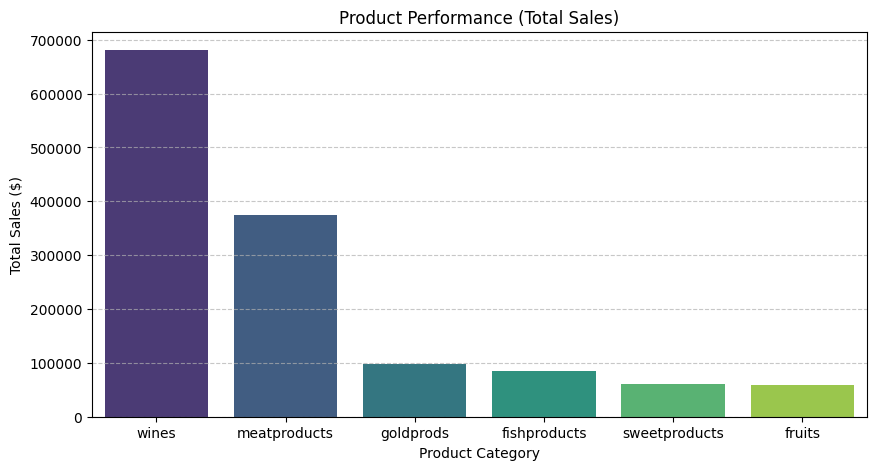

In [48]:
# Calculate total spending per product category
prod_data = data.filter(regex='^mnt').sum().reset_index()
prod_data.columns = ['Product', 'Total_Sales']
prod_data['Product'] = prod_data['Product'].str.replace('mnt', '')

# Plot the product performance
plt.figure(figsize=(10, 5))
sns.barplot(data=prod_data.sort_values(by='Total_Sales', ascending=False), x='Product', y='Total_Sales', palette='viridis')
plt.title('Product Performance (Total Sales)')
plt.xlabel('Product Category')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

9.2: Explore the relationship between age and campaign acceptance rate (acceptedcmp5) using a bar plot

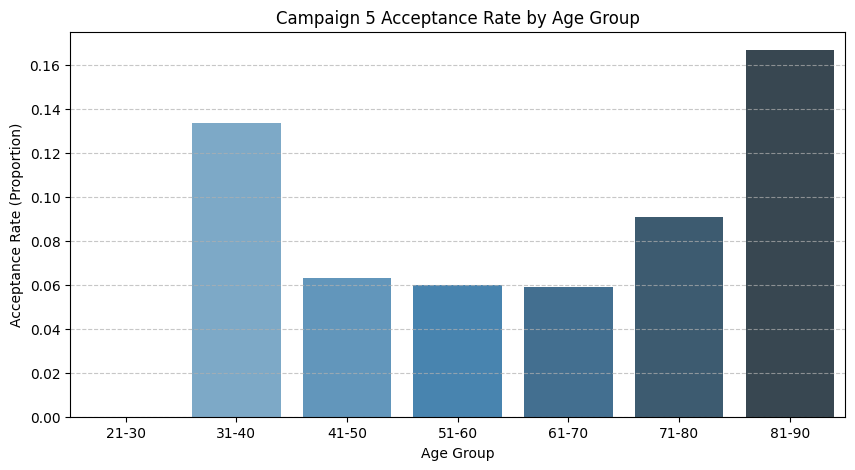

In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Bin age into decade categories for better visualization
data['age_group'] = pd.cut(data['age'], bins=[20, 30, 40, 50, 60, 70, 80, 90], labels=['21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90'])

# Calculate campaign acceptance rate (mean) for each age group
campaign_acceptance = data.groupby('age_group', observed=False)['acceptedcmp5'].mean().reset_index()

# Plot the results
plt.figure(figsize=(10, 5))
sns.barplot(data=campaign_acceptance, x='age_group', y='acceptedcmp5', hue='age_group', palette='Blues_d', legend=False)
plt.title('Campaign 5 Acceptance Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Acceptance Rate (Proportion)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

9.3: Determine the country with the most customers who accepted the last campaign using a bar plot

In [52]:
new_data = pd.concat([data,pd.get_dummies(data[['country', 'marital_status']])], axis = 1)
accptd_data = new_data.groupby('country')[['acceptedcmp5']].agg('sum').squeeze().sort_values(ascending = False)
plt.figure(figsize = (20,6))
sns.barplot(x = accptd_data.index, y = accptd_data.values, order=accptd_data.index)
for i in range(accptd_data.size):
  plt.annotate(accptd_data[i], xy = (i-0.05, accptd_data[i]+2), size =15 , weight = 'heavy')
plt.ylim(0,100)
plt.xlabel( 'Country', size = 20, color = 'green')
plt.ylabel( 'Customer accepting last campaign', size = 18, color = 'green')
plt.title('Country vs. Last campaign performance', size = 35, pad = 10, color = 'green')
plt.xticks(size = 14)
plt.show()

KeyError: "None of [Index(['country', 'marital_status'], dtype='object')] are in the [columns]"